# Семинар 5-СС. Аугментация стратегиялары есепке байланысты

Кестедегі әр есеп үшін **жарайтын** және **қауіпті** аугментацияны көрсетеміз, соңында тексереміз:
*аугментацияланған кескіндегі класты адам тани ала ма?* (MNIST үшін — дайын CNN моделімен де тексереміз).

| Есеп | Жарайды | Қауіпті |
|---|---|---|
| Жануарлар мен заттардың фотосы | шағылыстыру, қиып алу, түс, ±15° бұру | Іс жүзінде ештеңе |
| Қолжазба цифрлар | ығысу, ±10° бұру, шу | шағылыстыру, 180° бұру: 6 ↔ 9 |
| Жол белгілері | жарықтық, бұлыңғырлау, перспектива | шағылыстыру: «солға» ↔ «оңға» |
| Медициналық суреттер | ығысу, масштаб, контраст | түсті өзгерту, егер түс — белгі болса |
| Спутниктік суреттер | 90°-қа бұру, шағылыстыру | масштабты қатты өзгерту |

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
rng = np.random.default_rng(0)

# --- базалық аугментация функциялары (бәрі cv2/numpy) ---
def flip_h(img):  return img[:, ::-1].copy()
def rotate(img, deg, scale=1.0, border=cv2.BORDER_REFLECT):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, scale)
    return cv2.warpAffine(img, M, (w, h), borderMode=border)
def shift(img, dx, dy, border=cv2.BORDER_REFLECT):
    h, w = img.shape[:2]
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (w, h), borderMode=border)
def random_crop(img, frac=0.8):
    h, w = img.shape[:2]
    ch, cw = int(h * frac), int(w * frac)
    y, x = rng.integers(0, h - ch + 1), rng.integers(0, w - cw + 1)
    return cv2.resize(img[y:y + ch, x:x + cw], (w, h))
def color_jitter(img, b=30, s=1.3):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 1] = np.clip(hsv[..., 1] * s, 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] + b, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
def brightness(img, k): return np.clip(img.astype(np.float32) * k, 0, 255).astype(np.uint8)
def contrast(img, k):
    m = img.mean()
    return np.clip((img.astype(np.float32) - m) * k + m, 0, 255).astype(np.uint8)
def gauss_noise(img, sigma=15):
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)
def perspective(img, d=0.12):
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = (src + rng.uniform(-d, d, src.shape) * [w, h]).astype(np.float32)
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h), borderMode=cv2.BORDER_REFLECT)

def show_row(items, title, fname, cmap=None, size=2.6):
    """items: [(img, caption, ok)] — ok=True жасыл, False қызыл тақырып."""
    fig, axes = plt.subplots(1, len(items), figsize=(size * len(items), size + 0.6))
    for ax, (im, cap, ok) in zip(np.atleast_1d(axes), items):
        ax.imshow(im, cmap=cmap, vmin=0 if cmap else None, vmax=255 if cmap else None)
        ax.set_title(cap, fontsize=9, color={True: "green", False: "red", None: "black"}[ok])
        ax.axis("off")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=120)
    plt.show()

## Есеп 1. 

Жарайды: шағылыстыру, қиып алу, түс, ±15° бұру. Қауіпті ештеңе жоқ — сынып көлденең шағылыстырудан өзгермейді.

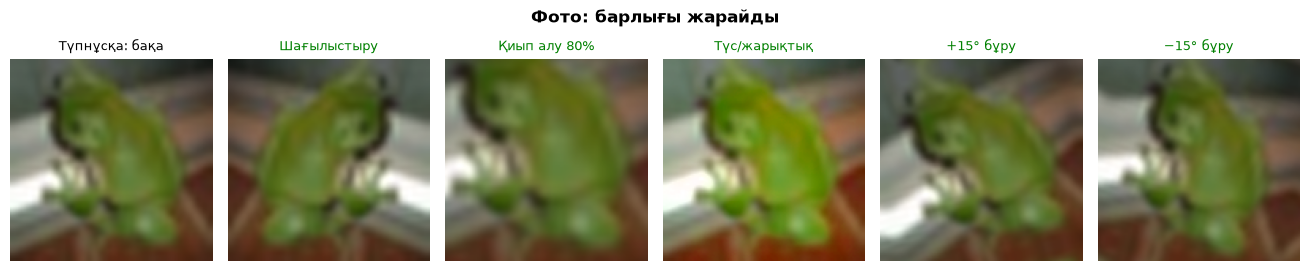

In [2]:
cifar = np.load("../1/datasets/cifar10.npz")
names = ["ұшақ", "көлік", "құс", "мысық", "бұғы", "ит", "бақа", "ат", "кеме", "жүк көлігі"]
i = 7
img = cv2.resize(cifar["x_test"][i], (128, 128), interpolation=cv2.INTER_CUBIC)
label = names[int(cifar["y_test"][i])]
show_row([
    (img, f"Түпнұсқа: {label}", None),
    (flip_h(img), "Шағылыстыру", True),
    (random_crop(img, 0.8), "Қиып алу 80%", True),
    (color_jitter(img), "Түс/жарықтық", True),
    (rotate(img, 15), "+15° бұру", True),
    (rotate(img, -15), "−15° бұру", True),
], "Фото: барлығы жарайды", "task1_photo_aug.png", size=2.2)

## Есеп 2. 

Жарайды: ығысу, ±10° бұру, шу. Қауіпті: шағылыстыру және 180° бұру (6 ↔ 9).

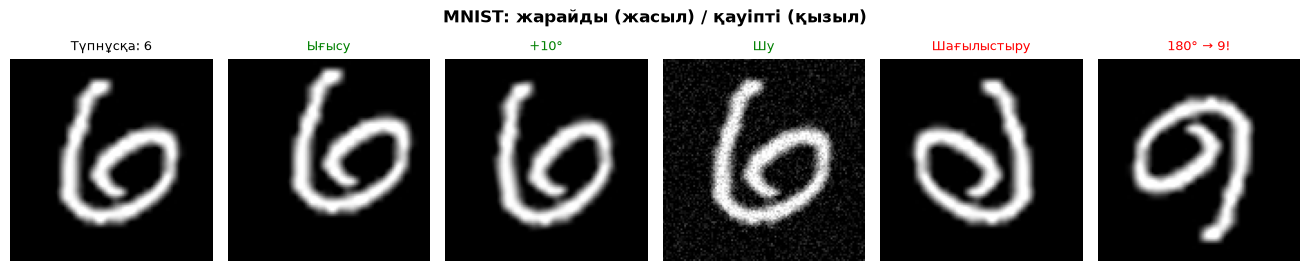

In [3]:
mnist = np.load("../1/datasets/mnist.npz")
xs, ys = mnist["x_test"], mnist["y_test"]
six = xs[np.where(ys == 6)[0][0]]
big = cv2.resize(six, (112, 112), interpolation=cv2.INTER_CUBIC)
show_row([
    (big, "Түпнұсқа: 6", None),
    (shift(big, 8, -6, cv2.BORDER_CONSTANT), "Ығысу", True),
    (rotate(big, 10, 1.0, cv2.BORDER_CONSTANT), "+10°", True),
    (gauss_noise(big, 25), "Шу", True),
    (flip_h(big), "Шағылыстыру", False),
    (rotate(big, 180, 1.0, cv2.BORDER_CONSTANT), "180° → 9!", False),
], "MNIST: жарайды (жасыл) / қауіпті (қызыл)", "task2_mnist_aug.png", cmap="gray", size=2.2)

### Тексеру: дайын MNIST CNN моделі аугментацияланған цифрды таниды ма?

Кіріс формасы: (None, 28, 28, 1)
Түпнұсқа           accuracy = 0.970
Ығысу ±2 px        accuracy = 0.807
Бұру ±10°          accuracy = 0.965
Шу σ=25            accuracy = 0.961
Шағылыстыру        accuracy = 0.429
Бұру 180°          accuracy = 0.399


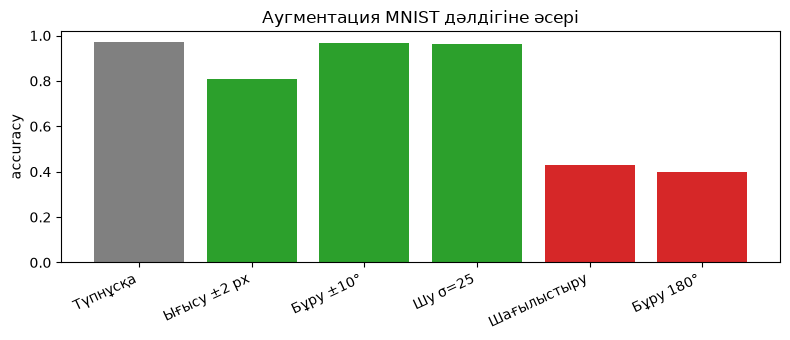

In [4]:
import tensorflow as tf
model = tf.keras.models.load_model("../1/model/mnist_cnn.keras")
print("Кіріс формасы:", model.input_shape)

def prep(batch): return (batch.astype("float32") / 255.0)[..., None]

n = 2000
X, Y = xs[:n], ys[:n]
augs = {
    "Түпнұсқа":          lambda a: a,
    "Ығысу ±2 px":       lambda a: shift(a, rng.integers(-2, 3), rng.integers(-2, 3), cv2.BORDER_CONSTANT),
    "Бұру ±10°":         lambda a: rotate(a, rng.uniform(-10, 10), 1.0, cv2.BORDER_CONSTANT),
    "Шу σ=25":           lambda a: gauss_noise(a, 25),
    "Шағылыстыру":       flip_h,
    "Бұру 180°":         lambda a: rotate(a, 180, 1.0, cv2.BORDER_CONSTANT),
}
accs = {}
for name, f in augs.items():
    Xa = np.stack([f(a) for a in X])
    accs[name] = float((model.predict(prep(Xa), verbose=0).argmax(1) == Y).mean())
    print(f"{name:18s} accuracy = {accs[name]:.3f}")

plt.figure(figsize=(8, 3.5))
plt.bar(accs.keys(), accs.values(), color=["gray"] + ["tab:green"] * 3 + ["tab:red"] * 2)
plt.xticks(rotation=25, ha="right"); plt.ylabel("accuracy"); plt.title("Аугментация MNIST дәлдігіне әсері")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "task2_mnist_accuracy.png"), dpi=120); plt.show()

**Қорытынды:** бұру мен шу кезінде дәлдік шамалы ғана төмендейді (ығысу — бұл модель аугментациясыз оқытылғандықтан сезімтал; оны оқыту кезінде қосу дәл осы үшін керек). Ал шағылыстыру/180° бұру кезінде күрт құлайды — 
өйткені класс өзгереді (6 ↔ 9) немесе цифр танылмай қалады. Мұндай аугментацияны **оқытуда қолдануға болмайды** (label noise).

## Есеп 3. Жол белгілері

Жарайды: жарықтық, бұлыңғырлау, перспектива. Қауіпті: шағылыстыру — «солға бұрылу» ↔ «оңға бұрылу».

Деректер жоқ, сондықтан «солға бұрылу» белгісін өзіміз салып аламыз.

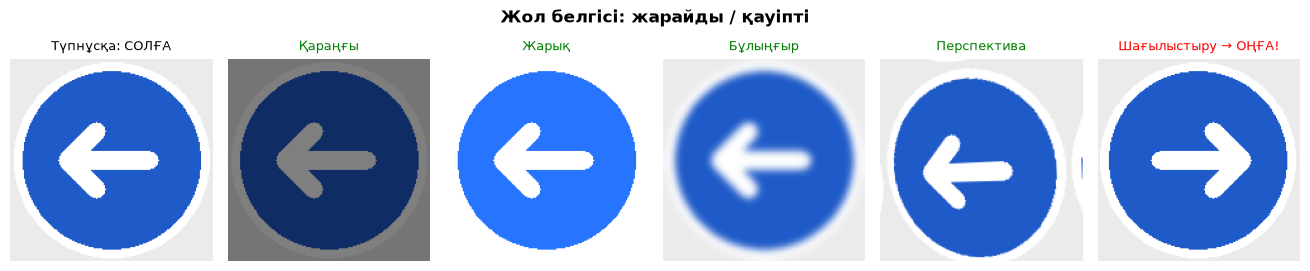

In [5]:
def make_sign(direction="left", n=160):
    im = np.full((n, n, 3), 235, np.uint8)
    cv2.circle(im, (n // 2, n // 2), n // 2 - 6, (30, 90, 200), -1)
    cv2.circle(im, (n // 2, n // 2), n // 2 - 6, (255, 255, 255), 6)
    a, b = (110, 80) if direction == "left" else (50, 80)
    tip = (45, 80) if direction == "left" else (115, 80)
    cv2.arrowedLine(im, (a if direction == "left" else b, 80), tip, (255, 255, 255), 14, tipLength=0.5)
    return im

sign = make_sign("left")
show_row([
    (sign, "Түпнұсқа: СОЛҒА", None),
    (brightness(sign, 0.5), "Қараңғы", True),
    (brightness(sign, 1.3), "Жарық", True),
    (cv2.GaussianBlur(sign, (0, 0), 3), "Бұлыңғыр", True),
    (perspective(sign, 0.1), "Перспектива", True),
    (flip_h(sign), "Шағылыстыру → ОҢҒА!", False),
], "Жол белгісі: жарайды / қауіпті", "task3_sign_aug.png", size=2.2)

## Есеп 4. 

Жарайды: ығысу, масштаб, контраст. Қауіпті: түсті өзгерту, егер түс — белгі болса (мысалы, гистологиядағы боялған ұлпа).

Үлгі ретінде сұр реңкті «фантом» (ақ дақ — ауру аймақ) және боялған ұлпа жасаймыз.

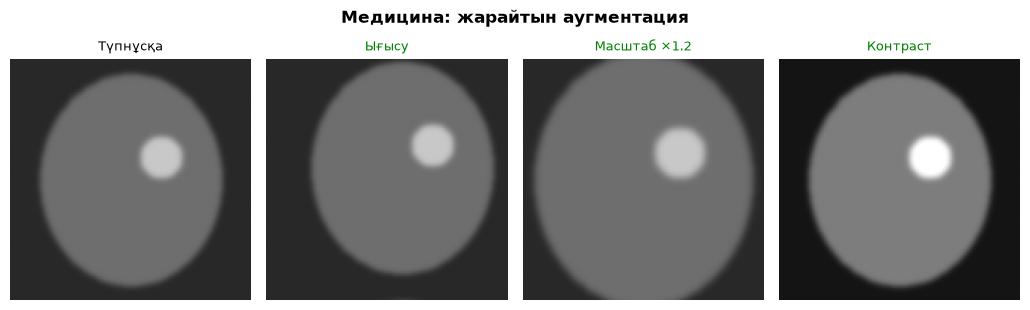

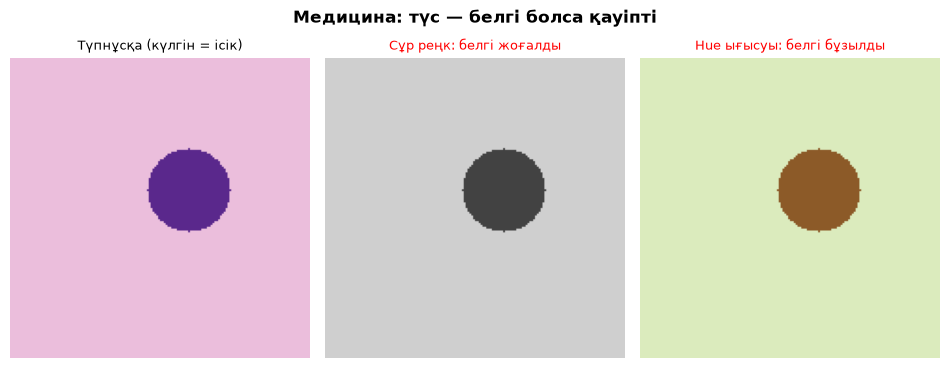

In [6]:
def phantom(n=160):
    im = np.full((n, n), 40, np.uint8)
    cv2.ellipse(im, (n // 2, n // 2), (60, 70), 0, 0, 360, 110, -1)
    cv2.circle(im, (n // 2 + 20, n // 2 - 15), 14, 200, -1)
    return cv2.GaussianBlur(im, (0, 0), 2)

ph = phantom()
tissue = np.zeros((160, 160, 3), np.uint8); tissue[:] = (235, 190, 220)     # H&E: қызғылт = қалыпты
cv2.circle(tissue, (95, 70), 22, (90, 40, 140), -1)                            # күлгін = ісік
tissue_gray = cv2.cvtColor(cv2.cvtColor(tissue, cv2.COLOR_RGB2GRAY), cv2.COLOR_GRAY2RGB)
tissue_hue = cv2.cvtColor(((cv2.cvtColor(tissue, cv2.COLOR_RGB2HSV).astype(int) + [60, 0, 0]) % [180, 256, 256]).astype(np.uint8), cv2.COLOR_HSV2RGB)

show_row([
    (ph, "Түпнұсқа", None),
    (shift(ph, 10, -8), "Ығысу", True),
    (rotate(ph, 0, 1.2), "Масштаб ×1.2", True),
    (contrast(ph, 1.5), "Контраст", True),
], "Медицина: жарайтын аугментация", "task4_medical_ok.png", cmap="gray", size=2.6)

show_row([
    (tissue, "Түпнұсқа (күлгін = ісік)", None),
    (tissue_gray, "Сұр реңк: белгі жоғалды", False),
    (tissue_hue, "Hue ығысуы: белгі бұзылды", False),
], "Медицина: түс — белгі болса қауіпті", "task4_medical_bad.png", size=3.2)

## Есеп 5. 

Жарайды: 90°-қа бұру, шағылыстыру (үстінен көру — бағыт жоқ). Қауіпті: масштабты қатты өзгерту — нысан өлшемі ақпарат болып табылады (ғимарат vs қала).

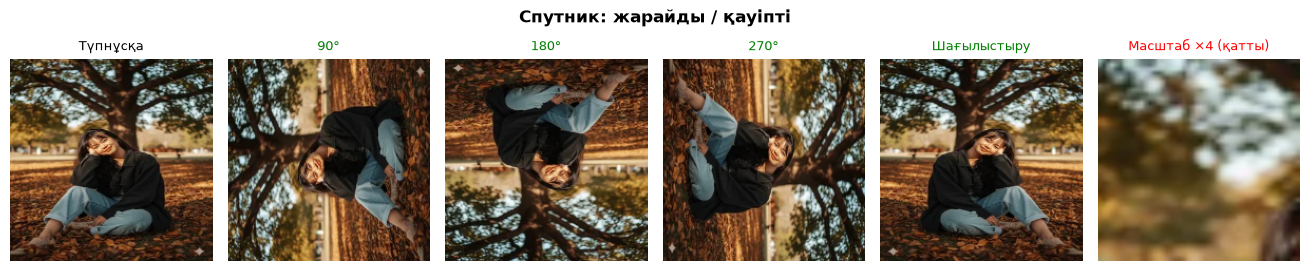

In [7]:
photo = cv2.cvtColor(cv2.imread("../4/images/photo.webp"), cv2.COLOR_BGR2RGB) if cv2.imread("../4/images/photo.webp") is not None else None
if photo is None:  # webp оқылмаса — CIFAR суретін қолданамыз
    photo = cv2.resize(cifar["x_test"][3], (192, 192))
photo = cv2.resize(photo, (192, 192))
show_row([
    (photo, "Түпнұсқа", None),
    (np.rot90(photo, 1), "90°", True),
    (np.rot90(photo, 2), "180°", True),
    (np.rot90(photo, 3), "270°", True),
    (flip_h(photo), "Шағылыстыру", True),
    (random_crop(photo, 0.25), "Масштаб ×4 (қатты)", False),
], "Спутник: жарайды / қауіпті", "task5_satellite_aug.png", size=2.2)

## Қорытынды

- Аугментация **есептің инварианттылығына** сәйкес таңдалады: ол класты өзгертпеуі керек.
- Тексеру ережесі: *аугментацияланған кескіндегі класты адам тани ала ма?* Жоқ болса (6 ↔ 9, солға ↔ оңға, түс — белгі) — ол аугментация қауіпті.
- MNIST эксперименті мұны сандармен растайды: қауіпті түрлендірулерде модель дәлдігі күрт төмендейді.